# Индекс новизны: динамика процесса и моменты окна

Задача проекта — одноклассовый поиск новизны. В обучении есть только исправные прогоны Tennessee Eastman, и порог ставится по их отложенной части. Метки отказов не участвуют ни в признаках, ни в выборе порога: файл неисправного обучения не читается.

Сначала окно описывают две статистики одного нормального класса. Канонический остаток проверяет, предсказывает ли прошлое его будущее. Моменты окна проверяют уровень и размах. У них общая квадратичная форма, а сумма в единицах нормального хвоста соединяет сбой динамики и сдвиг режима. После проверки вариантов, которые бьют в оставшиеся дыры, рабочей оценкой стала другая сборка тех же статистик: максимум трёх хвостов, включая медленные признаки, и экспоненциальное сглаживание вдоль прогона. Сумма в таблице остаётся как предыдущий шаг. Рядом три ориентира. Центроид — расстояние до среднего окна. Подпространство окна — классический динамический PCA. Свёрточный индекс — прямой перенос MiniRocket и MultiRocket: он показывает, какую часть классификации рядов эти отказы не затрагивают.


## Почему расстояние до среднего окна мало

Окно $X \in \mathbb{R}^{T \times C}$ уже приведено к нулевому среднему и единичному размаху **по каждому каналу на обучающих отсчётах**. После этого каналы всё ещё зависимы: давление, уровень и расход движутся вместе, а часть датчиков почти повторяет другие. Евклидова норма

$$
s(X) = \lVert \mathrm{vec}(X) - \mu \rVert_2
$$

считает шаг вдоль обычной корреляции таким же подозрительным, как шаг поперёк неё. Первое — нормальная вариация режима, второе — поломка связей. Нужна квадратичная форма с ковариацией нормального класса, а не шар.


## Совместный индекс $T^2$ и $Q$

Пусть $x = \mathrm{vec}(X) \in \mathbb{R}^{d}$, $d = TC$, и $S$ — ковариация исправных окон. Спектральное разложение оставляет $k$ ведущих компонент $P_k$ с собственными числами $\Lambda_k$. Окно длины $T$ — это лаговое наблюдение, поэтому такой PCA есть динамический PCA Ку, Сторера и Георгакиса.

$$
T^2(x) = \lVert \Lambda_k^{-1/2} P_k^{\mathsf T}(x-\mu)\rVert_2^2,
\qquad
Q(x) = \lVert (I-P_k P_k^{\mathsf T})(x-\mu)\rVert_2^2.
$$

$T^2$ велик, когда окно далеко вдоль тех направлений, где исправный процесс и так сильно гуляет. $Q$ велик, когда энергия осталась вне этого подпространства: связь между датчиками сломалась. Юэ и Цинь складывают их в один индекс, деля каждый член на его контрольный предел:

$$
\varphi(x) = \frac{T^2(x)}{\tau^2} + \frac{Q(x)}{\delta^2}.
$$

При гауссовых независимых наблюдениях пределы $\tau^2$ и $\delta^2$ берутся из распределения Фишера и аппроксимации Джексона–Мудхолкара. Здесь этого нет. Окна пересекаются, а часть признаков ниже ограничена, так что $\chi^2$ была бы декоративной. Предел заменяется эмпирическим квантилем уровня $1-\alpha$ по обучающим оценкам: единица индекса — это хвост нормального класса. Решение «тревога или нет» сюда не входит. Его принимает общий порог `threshold_at_fpr` по валидационным **прогонам**, а не по тем же окнам, на которых оценивалась ковариация.

Ранг $k$ выбирается без меток: наименьшее число компонент, объясняющее 90% дисперсии, но не больше 64. Мелкие собственные числа в $T^2$ не входят, иначе шум в почти пустом направлении взрывает расстояние; их энергия остаётся в $Q$.


## Канонические переменные

Подпространство окна отвечает на вопрос «необычно ли само наблюдение». Оно не проверяет, предсказывает ли прошлое будущее. Для этого окно делится пополам: $p$ — первая половина, $f$ — вторая. После вычитания среднего и деления на обучающий размах каждой координаты пара считается совместно нормальной. Тогда условный закон исправной работы

$$
f \mid p \sim \mathcal N(Bp,\; \Sigma_{f\mid p}),
\qquad
B = \Sigma_{pp}^{-1}\Sigma_{pf}.
$$

Это канонический анализ, в том виде, в каком его используют для мониторинга динамического процесса (Негиз и Чинар; Рассел, Чианг и Браатц): состояние — то в прошлом, что линейно связано с будущим, а новизна — либо необычное прошлое, либо остаток прогноза.

Две квадратичные статистики:

$$
s(p) = (p-\mu_p)^{\mathsf T}\Sigma_{pp}^{-1}(p-\mu_p),
\qquad
s(f\mid p) = (f-Bp)^{\mathsf T}\Sigma_{f\mid p}^{-1}(f-Bp).
$$

Первая поднимается, когда процесс ушёл из обычной области, даже если переход ещё похож на нормальный. Вторая поднимается, когда переход сломался: клапан залип, коэффициент усиления изменился, а среднее ещё не успело уехать. В сумму они входят каждый в единицах своего обучающего квантиля $1-\alpha$.

При $C = 52$ и половине окна в 12 отсчётов размерность блока — 624. Выборочная ковариация тут ещё обратима, но мелкие собственные числа шумные. Поэтому $\Sigma_{pp}$ и ковариация остатка заменяются оценкой Ледуа–Вулфа

$$
\hat\Sigma_{\rho} = (1-\rho)S + \rho\,\frac{\mathrm{tr}(S)}{p}\,I.
$$

$\rho$ минимизирует среднеквадратичную ошибку в режиме, где размерность не мала по сравнению с числом окон. Усадка поднимает пол собственных чисел и не даёт одному направлению шума определять тревогу. Если блок шире `max_block_dim`, он сначала проецируется на ведущие компоненты, а отброшенная энергия добавляется отдельным слагаемым; при окне 24 и 52 каналах этого усечения нет.


## Что от классификации рядов переносится, а что нет

Текущий практический потолок классификации рядов — семейство ROCKET. MiniRocket сворачивает окно ядрами длины 9 с весами $\{-1, 2\}$: три двойки и шесть минус единиц, всего $\binom{9}{3} = 84$ ядра. Сумма весов равна нулю, так что отклик не зависит от постоянной составляющей. Дилатации стоят на логарифмической сетке, канал для мультивариата — случайная сумма не более чем девяти рядов, признак — доля положительных откликов. MultiRocket добавляет первую разность и среднее положительных откликов. В классификации на этих признаках учат ридж-регрессию. Отрицательного класса здесь нет, поэтому вместо неё стоит тот же совместный индекс $T^2+Q$, уже со стандартизацией признаков: доля положительных лежит в $[0,1]$, а среднее отклика — нет.

Эта замена отвечает на постановку проекта буквально и почти не работает на ступенчатых отказах TEP. Окно, целиком лежащее в новом установившемся режиме, отличается от исправного **уровнем**, а не формой. Нулевая сумма ядра этот уровень стирает. Первая разность нового уровня тоже нулевая. Индекс в пространстве таких признаков видит залипание, дрожь и смену масштаба колебаний и не видит чистый сдвиг датчика или клапана.

Сдвиг и размах никуда не делись: это среднее и стандартное отклонение каждого канала внутри окна, вектор длины $2C$. Его расстояние Махаланобиса с той же усадкой Ледуа–Вулфа — вторая статистика. Ковариация нужна и здесь. После общей стандартизации каналы остаются связанными, и шаг всех расходов вместе не должен стоить столько же, сколько шаг одного расхода против остальных.

Свёрточный индекс в сравнении остаётся. Он проверяет границу переноса, а не дополняет сумму: на короткой выборке хвост этих признаков не улучшал ни раннее обнаружение, ни AUROC относительно динамики и моментов.


## Сумма хвостов

У канонической оценки и у моментов разные единицы. Деление на обучающий квантиль уровня $1-\alpha$ переводит каждую в «сколько её собственных нормальных хвостов стоит это окно». Сумма

$$
s(X) = \frac{s_{\mathrm{cva}}(X)}{q_{1-\alpha}(s_{\mathrm{cva}})} + \frac{s_{\mathrm{mom}}(X)}{q_{1-\alpha}(s_{\mathrm{mom}})}
$$

не отдаёт решение той статистике, у которой числа просто крупнее. Окно, необычное только для одной из них, всё равно поднимает сумму. Порог по-прежнему один, по валидации, с потолком доли ложных тревог 0.01. Квантиль $\alpha = 0.01$ задаёт только взаимный вес слагаемых.

Обучающий квантиль считается по тем же окнам, что и ковариация, поэтому он чуть оптимистичен. На решение это не влияет: порог стоит на других прогонах. Страдает только баланс двух слагаемых, и одинаково для обеих сторон.


## Окна

Длина 24 и шаг 8 общие для всех моделей. Первое окно, которое можно засчитать как отказ, начинается на 161-м отсчёте и заканчивается на 184-м, так что задержка короче 24 отсчётов, то есть 72 минут, невозможна по построению паспорта. Шаг 8 попадает в отсчёт 161, если ряд начинается с 1. Каналы — все 52: у части отказов измерение удерживает регулятор, а сдвигается управляющий клапан.

Неисправности 3, 9 и 15 в мониторинге TEP считаются труднообнаружимыми. Третья и девятая — температура потока D, пятнадцатая — залипание клапана конденсатора; в измерениях от них остаётся слабый сдвиг. В сводке они не усредняются с остальными.


In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from industrial_novelty import (
    CanonicalVariateIndex,
    CentroidDistance,
    ConvolutionalKernelIndex,
    ExperimentConfig,
    SlowFeatureIndex,
    TailMax,
    TailSum,
    WindowMomentIndex,
    WindowSubspaceIndex,
    WithinRunEWMA,
    build_experiment,
    evaluate_model,
)

experiment = build_experiment(
    ExperimentConfig(window_size=24, stride=8, channels="all")
)
experiment.counts()

,split,n_windows,n_runs,window_size,n_channels
0,train,24000,400,24,52
1,val,6000,100,24,52
2,normal_test,59000,500,24,52


## Сравнение

Центроид — ориентир из предыдущего ноутбука. Подпространство окна — совместный индекс $T^2+Q$ по развёрнутому окну. Моменты и канонические переменные — слагаемые суммы. Свёрточный индекс — MiniRocket/MultiRocket без линейной головы. Сумма хвостов — предыдущая сборка. Карта по прогону — максимум хвостов канонических переменных, моментов и медленных признаков, затем EWMA с весом 0.2 и сбросом на границе `simulationRun`.


In [2]:
specs = [
    ("центроид", CentroidDistance()),
    ("подпространство окна", WindowSubspaceIndex()),
    ("моменты окна", WindowMomentIndex()),
    ("канонические переменные", CanonicalVariateIndex()),
    ("свёрточные признаки", ConvolutionalKernelIndex()),
    (
        "сумма хвостов",
        TailSum((CanonicalVariateIndex(), WindowMomentIndex())),
    ),
    (
        "карта по прогону",
        WithinRunEWMA(
            TailMax(
                (
                    CanonicalVariateIndex(),
                    WindowMomentIndex(),
                    SlowFeatureIndex(),
                )
            ),
            lam=0.2,
        ),
    ),
]

reports = {}
fitted = {}
for name, model in specs:
    started = time.perf_counter()
    model.fit(experiment.train.X)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    reports[name] = evaluate_model(model, experiment, target_fpr=0.01)
    eval_seconds = time.perf_counter() - started
    fitted[name] = model
    print(
        f"{name}: обучение {fit_seconds:.0f} с, оценка {eval_seconds:.0f} с, "
        f"{reports[name]}",
        flush=True,
    )

print(fitted["подпространство окна"])
print(fitted["моменты окна"])
print(fitted["канонические переменные"])
print(fitted["свёрточные признаки"])

центроид: обучение 0 с, оценка 28 с, DetectionReport(threshold=46.61, target_fpr=0.01, normal_test_fpr=0.0179, false_alarm_run_rate=0.438, faults=20)


подпространство окна: обучение 1 с, оценка 22 с, DetectionReport(threshold=1.875, target_fpr=0.01, normal_test_fpr=0.011, false_alarm_run_rate=0.592, faults=20)


моменты окна: обучение 0 с, оценка 19 с, DetectionReport(threshold=0.9999, target_fpr=0.01, normal_test_fpr=0.0135, false_alarm_run_rate=0.54, faults=20)


канонические переменные: обучение 1 с, оценка 34 с, DetectionReport(threshold=1.955, target_fpr=0.01, normal_test_fpr=0.0108, false_alarm_run_rate=0.604, faults=20)


свёрточные признаки: обучение 10 с, оценка 446 с, DetectionReport(threshold=1.913, target_fpr=0.01, normal_test_fpr=0.00969, false_alarm_run_rate=0.622, faults=20)


сумма хвостов: обучение 2 с, оценка 40 с, DetectionReport(threshold=1.969, target_fpr=0.01, normal_test_fpr=0.0128, false_alarm_run_rate=0.502, faults=20)


карта по прогону: обучение 3 с, оценка 47 с, DetectionReport(threshold=1.866, target_fpr=0.01, normal_test_fpr=0.0177, false_alarm_run_rate=0.302, faults=20)


WindowSubspaceIndex(rank=64, variance=0.9)
WindowMomentIndex(shrinkage=0.000)
CanonicalVariateIndex(past_dim=624, future_dim=624, past_shrinkage=0.001)
ConvolutionalKernelIndex(n_features=6720, rank=48, differences=True)


In [3]:
HARD = {3, 9, 15}


def summary_row(name: str, report) -> dict[str, object]:
    table = report.per_fault
    hard = table["fault_number"].isin(HARD)
    easy = table.loc[~hard]
    return {
        "модель": name,
        "FPR окон": report.normal_test_fpr,
        "доля прогонов с тревогой": report.false_alarm_run_rate,
        "обнаружение, кроме 3/9/15": easy["detection_rate"].mean(),
        "раннее обнаружение, кроме 3/9/15": easy["early_detection_rate"].mean(),
        "медиана задержки, мин": easy["median_delay_minutes"].median(),
        "медиана AUROC, кроме 3/9/15": easy["auroc"].median(),
        "средний AUROC 3/9/15": table.loc[hard, "auroc"].mean(),
    }


summary = pd.DataFrame(summary_row(name, report) for name, report in reports.items())
summary

,модель,FPR окон,доля прогонов с тревогой,"обнаружение, кроме 3/9/15","раннее обнаружение, кроме 3/9/15","медиана задержки, мин","медиана AUROC, кроме 3/9/15",средний AUROC 3/9/15
0,центроид,0.017915,0.438,0.980118,0.546118,72.0,0.988874,0.539040
1,подпространство окна,0.011034,0.592,1.000000,0.628471,72.0,0.998474,0.531931
2,моменты окна,0.013508,0.540,1.000000,0.786353,72.0,1.000000,0.642773
3,канонические переменные,0.010763,0.604,1.000000,0.797059,72.0,0.999998,0.641214
4,свёрточные признаки,0.009695,0.622,0.974353,0.568235,72.0,0.936387,0.517055
5,сумма хвостов,0.012780,0.502,1.000000,0.797765,72.0,1.000000,0.668756
6,карта по прогону,0.017746,0.302,1.000000,0.776118,72.0,0.999998,0.818169


Доля обнаруженных прогонов по каждой неисправности. Единица значит, что порог, выставленный на 1% валидационных окон, сработал хотя бы на одном окне отказа до аварийного останова.


In [4]:
detection = pd.DataFrame(
    {
        name: report.per_fault.set_index("fault_number")["detection_rate"]
        for name, report in reports.items()
    }
)
detection.round(3)

,центроид,подпространство окна,моменты окна,канонические переменные,свёрточные признаки,сумма хвостов,карта по прогону
fault_number,,,,,,,
1,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,1.000,1.000,1.000,1.000,1.000,1.000,1.000
3,0.432,0.556,0.900,0.888,0.564,0.936,0.738
4,1.000,1.000,1.000,1.000,0.564,1.000,1.000
5,1.000,1.000,1.000,1.000,1.000,1.000,1.000
6,1.000,1.000,1.000,1.000,1.000,1.000,1.000
7,1.000,1.000,1.000,1.000,1.000,1.000,1.000
8,1.000,1.000,1.000,1.000,1.000,1.000,1.000
9,0.464,0.570,0.864,0.986,0.572,0.926,0.890


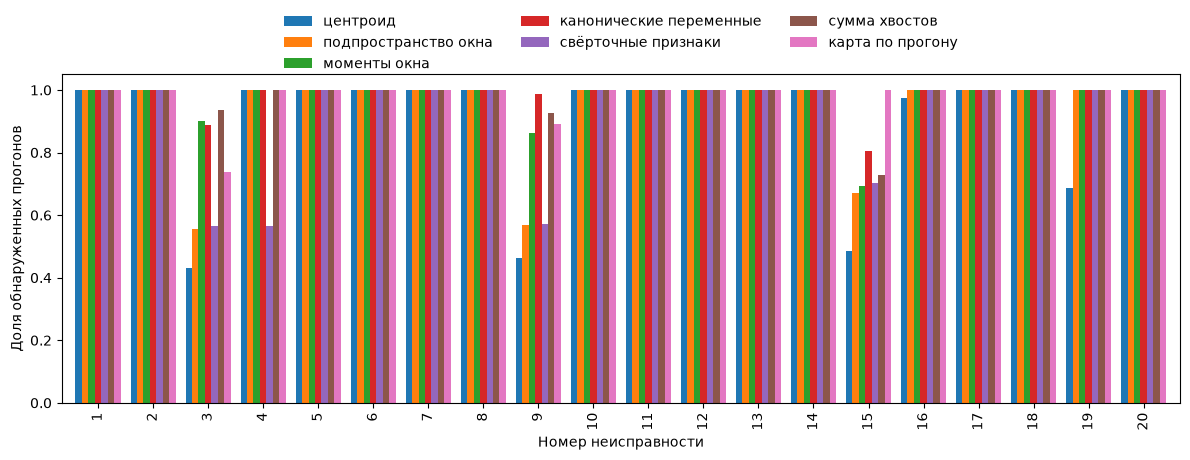

In [5]:
fig, axis = plt.subplots(figsize=(12, 4.8))
detection.plot.bar(ax=axis, width=0.82)
axis.set_xlabel("Номер неисправности")
axis.set_ylabel("Доля обнаруженных прогонов")
axis.set_ylim(0, 1.05)
axis.legend(
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.22),
)
fig.tight_layout()

Подробный отчёт карты по прогону. Задержка в минутах считается только по пойманным прогонам и не может быть меньше 72. Раннее обнаружение — доля прогонов, пойманных на первом допустимом окне.


In [6]:
columns = [
    "fault_number",
    "detection_rate",
    "early_detection_rate",
    "median_alarm_persistence",
    "median_delay_minutes",
    "auroc",
]
reports["карта по прогону"].per_fault.loc[:, columns].round(3)

,fault_number,detection_rate,early_detection_rate,median_alarm_persistence,median_delay_minutes,auroc
0,1,1.000,1.000,1.000,72.0,1.000
1,2,1.000,1.000,1.000,72.0,1.000
2,3,0.738,0.016,0.041,1008.0,0.749
3,4,1.000,1.000,1.000,72.0,1.000
4,5,1.000,1.000,1.000,72.0,1.000
5,6,1.000,1.000,1.000,72.0,1.000
6,7,1.000,1.000,1.000,72.0,1.000
7,8,1.000,0.842,1.000,72.0,0.999
8,9,0.890,0.014,0.092,768.0,0.809
9,10,1.000,0.474,0.990,96.0,0.996


Один прогон неисправностей 4 и 11. Четвёртая — ступень температуры охлаждающей воды реактора: измерение регулятор удерживает, сдвигается клапан. Одиннадцатая — случайные колебания той же температуры. Оценка поделена на порог модели, поэтому горизонталь 1 — это тревога. Вертикаль — 160-й отсчёт, последний исправный. Карта по прогону сглажена вдоль прогона, поэтому одиночный всплеск у неё ниже, чем у суммы.


Text(0.5, 0, 'Последний отсчёт окна')

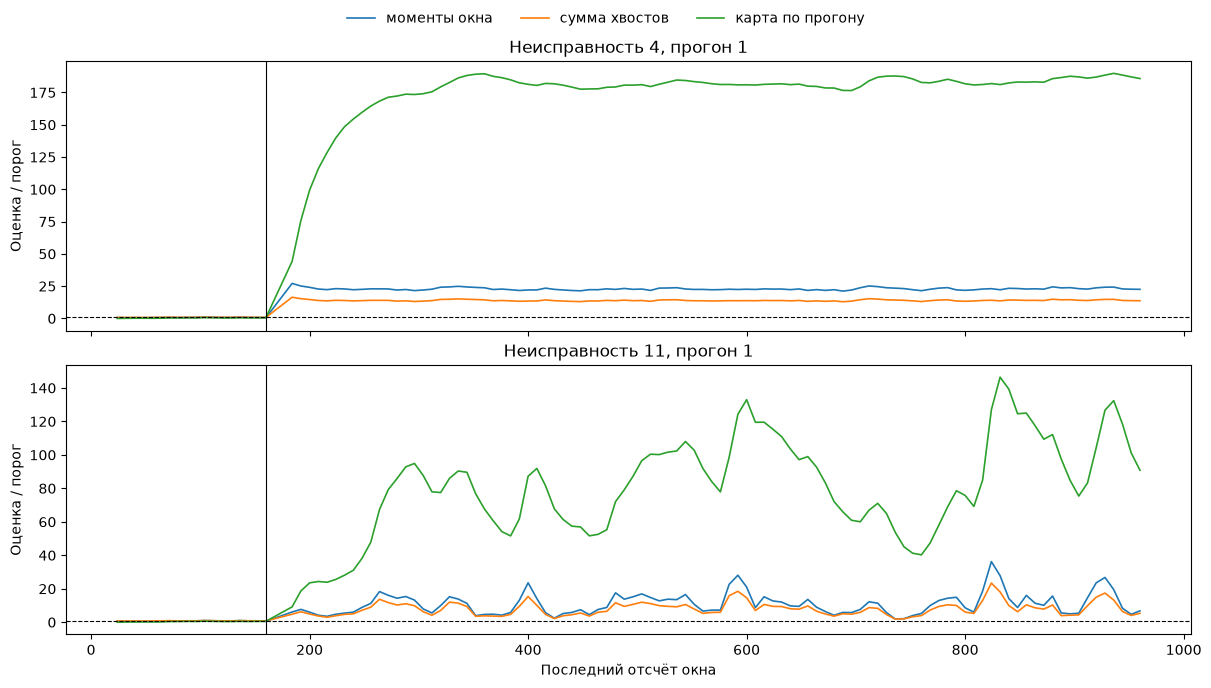

In [7]:
def alarm_units(model_name: str, fault_number: int) -> pd.DataFrame:
    fault = experiment.faulty_test(fault_number)
    run = int(fault.simulation_runs[0])
    meta = fault.batch.meta
    chosen = meta["simulation_run"].to_numpy() == run
    scores = fitted[model_name].score(fault.batch.X[chosen])
    part = meta.loc[chosen, ["sample_end", "label", "post_shutdown"]].copy()
    part["alarm_units"] = scores / reports[model_name].threshold
    return part.reset_index(drop=True)


fig, axes = plt.subplots(2, 1, figsize=(12, 6.8), sharex=True, layout="constrained")
shown = ("моменты окна", "сумма хвостов", "карта по прогону")
for axis, fault_number in zip(axes, (4, 11), strict=True):
    for name in shown:
        trace = alarm_units(name, fault_number)
        axis.plot(trace["sample_end"], trace["alarm_units"], label=name, linewidth=1.2)
    axis.axhline(1.0, color="black", linewidth=0.8, linestyle="--")
    axis.axvline(160, color="black", linewidth=0.8)
    axis.set_ylabel("Оценка / порог")
    run = int(experiment.faulty_test(fault_number).simulation_runs[0])
    axis.set_title(f"Неисправность {fault_number}, прогон {run}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, frameon=False)
axes[1].set_xlabel("Последний отсчёт окна")

## Что из этого следует

Карта по прогону — модель, которую стоит нести дальше. На наблюдаемых отказах она, как и сумма, находит каждый прогон. Раннее обнаружение 0.78 против 0.80 у суммы, медианная задержка та же, 72 минуты: сглаживание почти не отодвигает ступень, которая и так далеко над порогом. Доля исправных прогонов с тревогой падает с 0.50 до 0.30. Оконный FPR на нормальном тесте 0.018 при заданном 0.01.

Отказ 15 находится во всех прогонах, у суммы — в 0.73. Медианная задержка по нему 216 минут против 912, доля тревожных окон 0.53 против 0.01. Его вытаскивает медленный признак, а максимум не даёт двум другим статистикам этот сигнал разбавить. Отказ 9 почти тот же по доле прогонов, 0.89 против 0.93, при AUROC 0.81 против 0.67. Отказ 3 слабее: доля прогонов 0.74 против 0.94, медианная задержка 1008 минут против 576. Средний AUROC этих трёх — 0.82 против 0.67.

Вес EWMA 0.2 взят до просмотра отказов, из диапазона карт для небольшого сдвига (Lucas, Saccucci, Technometrics, 1990). Это скалярная карта Робертса по уже готовой оценке, не векторный MEWMA по сырым датчикам: контракт модели по-прежнему одно число на окно, а состояние живёт только внутри прогона.

Остальные варианты на полном тесте баланс не улучшили. Максимум только канонических переменных и моментов поднимает отказы 9 и 15 до 0.99 и 0.79, но тревога появляется уже в 0.62 исправных прогонов. Два соседних окна не срезают ложные тревоги: окна пересекаются, всплеск попадает в оба, а первое окно отказа сравнивается с ещё нормальным, и раннее обнаружение падает до 0.02. CUSUM поднимает устойчивость слабых отказов до 0.29, а оконный FPR на нормальном тесте уходит к 0.041. Окно длины 12 снижает медиану задержки до 36 минут и доводит отказ 15 до 0.92, при этом тревога есть в 0.77 исправных прогонов. Сумма с медленными признаками без максимума находит отказ 15 полностью и роняет отказы 3 и 9 до 0.65. Неглубокий автокодировщик развёрнутого окна даёт раннее обнаружение 0.63 и обнаружение 3/9/15 около 0.56. Порог только по непересекающимся валидационным окнам оставляет оконный FPR около 0.014.

Центроид на этих же окнах теряет отказ 19 и ловит наблюдаемый отказ на первом окне в 0.55 прогонов. Карта сохраняет обнаружение суммы и добавляет отказ 15.


## Литература

Окно как лаговое наблюдение и пара $T^2$, $Q$: Ku W., Storer R.H., Georgakis C. Disturbance detection and isolation by dynamic principal component analysis. Chemometrics and Intelligent Laboratory Systems, 1995. Совместный индекс: Yue H.H., Qin S.J. Reconstruction-based fault identification using a combined index. Industrial & Engineering Chemistry Research, 2001. Гауссов предел остатка, которым здесь пользуются только как мотивировкой, а не как порогом: Jackson J.E., Mudholkar G.S. Control procedures for residuals associated with principal component analysis. Technometrics, 1979.

Канонические переменные в мониторинге: Negiz A., Çinar A. Statistical monitoring of multivariable dynamic processes with state-space models. AIChE Journal, 1997. Russell E.L., Chiang L.H., Braatz R.D. Fault detection in industrial processes using canonical variate analysis and dynamic principal component analysis. Chemometrics and Intelligent Laboratory Systems, 2000.

Усадка ковариации: Ledoit O., Wolf M. A well-conditioned estimator for large-dimensional covariance matrices. Journal of Multivariate Analysis, 2004.

Свёрточные признаки: Dempster A., Schmidt D.F., Webb G.I. MiniRocket: A very fast (almost) deterministic transform for time series classification. KDD, 2021. Tan C.W., Dempster A., Bergmeir C., Webb G.I. MultiRocket: multiple pooling operators and transformations for fast and effective time series classification. Data Mining and Knowledge Discovery, 2022.

Процесс и данные: Downs J.J., Vogel E.F. A plant-wide industrial process control problem. Computers & Chemical Engineering, 1993. Chiang L.H., Russell E.L., Braatz R.D. Fault Detection and Diagnosis in Industrial Systems. Springer, 2001. Rieth et al. Additional Tennessee Eastman process simulation data for anomaly detection evaluation. Harvard Dataverse, 2017. Сравнение глубоких реконструкций на этом процессе: Hartung F. et al. Deep anomaly detection on Tennessee Eastman process data. Chemie Ingenieur Technik, 2023. Реконструкция там в среднем сильнее прогноза; здесь оставлен квадратичный остаток, потому что порог выбирается без меток, а независимых прогонов — несколько сотен, не миллионы окон.
